# Week 3: Calibration-First Baseline Models

<sub>[Previous: Feature Engineering and the Leakage Audit](week2_01_features_and_leakage.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Week 2 gave us a leakage-safe feature matrix and a warning: the legitimate signals are weak, so we should expect a modest model. This week we train the first models and find out exactly how modest. The discipline of the week is to judge them the right way. With a rare outcome, accuracy is worse than useless, so we lead with rate-aware metrics and, above all, calibration, because the whole equity analysis later depends on the risk scores meaning what they say.

### Contents

1. [Setup: read back the verified results](#setup)
2. [Why accuracy is the wrong metric](#accuracy)
3. [The honest performance ceiling](#ceiling)
4. [Calibration: the metric we actually care about](#calibration)
5. [Does calibration hold across race groups?](#byrace)
6. [The plan from here](#plan)

<a id="setup"></a>
## Setup: read back the verified results

The models were trained by a tested script (`scripts/week3_baselines.py`) on the leakage-safe matrix, and evaluated on the untouched held-out partition. We read those results back here rather than retraining in a cell, which keeps the notebook fast and the numbers reproducible.

In [1]:
# Week 3 reports models, so we mostly read back the results our tested pipeline already computed on the
# full data, rather than retraining in the notebook (training 500K rows belongs in a script, not a
# cell). The metrics come from reports/week3_baseline_metrics.json, written by scripts/week3_baselines.py
# which trains on the leakage-safe matrix from Week 2 and evaluates on the untouched 1.5M-row held-out
# partition. We do a little live computation on the modeling parquet for the intuition plots.
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RNG = 7

REPORTS = Path("..") / "reports"
M = json.loads((REPORTS / "week3_baseline_metrics.json").read_text())
DATA = Path("..") / "data" / "processed" / "modeling_full_2018_2024.parquet"

PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999", "ink": "#1a1a2e"}
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); return ax

# Self-contained: load a slim projection of the modeling working set so the notebook stands alone
# and can show real rows. We read only a few columns to stay light.
SAMPLE_COLS = ["preterm", "split", "mother_race_ethnicity", "mager", "meduc", "bmi",
               "medical_risk_count", "rf_ppterm", "first_trimester_care"]
mdf = pl.read_parquet(DATA, columns=SAMPLE_COLS)


Each notebook stands on its own, so here are real rows of the leakage-safe pre-delivery feature matrix (built in Week 2) that the models train on. The `split` column marks the deterministic train/val/test/held-out partitions, so every row is tagged with the fold it belongs to and nothing leaks across them.

In [2]:
mdf.sample(5, seed=RNG).to_pandas()

,preterm,split,mother_race_ethnicity,mager,meduc,bmi,medical_risk_count,rf_ppterm,first_trimester_care
0,1,held_out_final,NH White,33.0,3,20.400000,0,0,1
1,0,held_out_final,Hispanic,21.0,3,35.900002,0,0,0
2,0,held_out_final,NH Asian,38.0,7,18.900000,0,0,1
3,0,held_out_final,NH White,30.0,3,24.400000,0,0,1
4,0,dev_train,NH White,31.0,8,19.600000,0,0,1


In [3]:
print(f"Held-out evaluation set: {M['held_out_n']:,} singleton births, "
      f"prevalence {M['prevalence']*100:.2f}% preterm, {M['n_features']} pre-delivery features.")
print('Models trained (each with balanced class weights, isotonic-recalibrated):')
for name in M['models']: print('  -', name)

Held-out evaluation set: 1,498,760 singleton births, prevalence 8.57% preterm, 103 pre-delivery features.
Models trained (each with balanced class weights, isotonic-recalibrated):
  - logistic_regression
  - decision_tree
  - random_forest


<a id="accuracy"></a>
## Why accuracy is the wrong metric

Before any model, one number settles the choice of metric. The outcome is about 8.6% positive, so a model that simply predicts 'not preterm' for everyone is right about 91.4% of the time. Let me state that plainly, because it is the trap a lot of health-ML projects fall into.

In [4]:
base = M['prevalence']
print(f'Preterm prevalence: {base*100:.1f}%')
print(f'"Always predict not-preterm" accuracy: {(1-base)*100:.1f}%')
print('...which catches ZERO real preterm births. Accuracy rewards the useless model here.')

Preterm prevalence: 8.6%
"Always predict not-preterm" accuracy: 91.4%
...which catches ZERO real preterm births. Accuracy rewards the useless model here.


So accuracy is off the table. We report **AUC-PR** (the area under the precision-recall curve, the right summary when positives are rare), **AUC-ROC** (which is base-rate invariant, so it is the fair thing to compare across race groups), and calibration. Not accuracy.

Here is why the two AUC metrics play different roles. AUC-PR has a floor that equals the prevalence, so under this much imbalance it is the honest primary metric: a useless model cannot hide behind a high number. AUC-ROC has a fixed 0.5 floor regardless of the base rate, so it is base-rate invariant, which is exactly what makes it the fair comparator across race groups whose prevalence differs.

In [5]:
base = M['prevalence']
print(f"Prevalence (positive base rate): {base*100:.2f}%")
print(f"A random classifier's AUC-PR floor equals prevalence ({base:.3f}); AUC-ROC floor is 0.5.")
print('AUC-PR is the honest primary metric under this imbalance; AUC-ROC is base-rate invariant, so')
print('it is the fair thing to compare ACROSS race groups with different prevalence.')

Prevalence (positive base rate): 8.57%
A random classifier's AUC-PR floor equals prevalence (0.086); AUC-ROC floor is 0.5.
AUC-PR is the honest primary metric under this imbalance; AUC-ROC is base-rate invariant, so
it is the fair thing to compare ACROSS race groups with different prevalence.


<a id="ceiling"></a>
## The honest performance ceiling

Here are the three baselines on the held-out set. I am watching AUC-ROC for the headline (how much signal is really here) and AUC-PR as the primary rare-event metric.

In [6]:
rows = [(n, m['auc_roc'], m['auc_pr'], m['auc_pr_ci']) for n, m in M['models'].items()]
print(f"{'model':<22}{'AUC-ROC':>9}{'AUC-PR':>9}   95% CI (AUC-PR)")
for n, roc, pr, ci in rows:
    print(f'{n:<22}{roc:>9.3f}{pr:>9.3f}   [{ci[0]:.3f}, {ci[1]:.3f}]')
best = max(M['models'], key=lambda k: M['models'][k]['auc_roc'])
print(f'\nBest baseline: {best} at AUC-ROC {M["models"][best]["auc_roc"]:.3f}')

model                   AUC-ROC   AUC-PR   95% CI (AUC-PR)
logistic_regression       0.634    0.159   [0.155, 0.162]
decision_tree             0.626    0.150   [0.147, 0.154]
random_forest             0.651    0.166   [0.163, 0.170]

Best baseline: random_forest at AUC-ROC 0.651


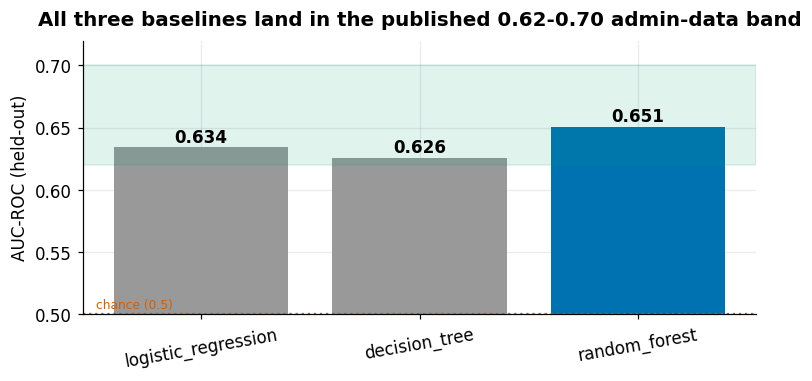

In [7]:
names = list(M['models']); rocs = [M['models'][n]['auc_roc'] for n in names]
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.bar(names, rocs, color=[PALETTE['grey'], PALETTE['grey'], PALETTE['blue']])
for i, v in enumerate(rocs): ax.text(i, v+0.004, f'{v:.3f}', ha='center', fontweight='bold')
ax.axhspan(0.62, 0.70, color=PALETTE['green'], alpha=0.12)
ax.axhline(0.5, ls=':', color=PALETTE['red'])
ax.text(0.02, 0.505, 'chance (0.5)', color=PALETTE['red'], fontsize=8, transform=ax.get_yaxis_transform())
style(ax, 'All three baselines land in the published 0.62-0.70 admin-data band', '', 'AUC-ROC (held-out)')
ax.set_ylim(0.5, 0.72); plt.xticks(rotation=10); plt.tight_layout(); plt.show()

**About 0.65, and I am glad it is not higher.** The best baseline (a random forest) reaches AUC-ROC around 0.65, with logistic regression close behind. The green band is the range that peer-reviewed models built from administrative or birth-certificate data typically report (roughly 0.62 to 0.70); richer clinical or biomarker data goes higher, but we do not have that, and honesty about it matters. This is the payoff of Week 2: because we barred the at-delivery fields, we get an honest 0.65 instead of a fraudulent 0.92. A number in this band is exactly what a trustworthy birth-certificate model should look like.

<a id="calibration"></a>
## Calibration: the metric we actually care about

Discrimination (AUC) is only half the story. For an equity audit, what matters even more is **calibration**: when the model says 10% risk, does the real rate turn out to be about 10%? If the scores are not calibrated, every fairness comparison built on them is meaningless. So we recalibrate each model (isotonic regression, fit on a separate slice the model never trained on) and measure the calibration error before and after.

In [8]:
print(f"{'model':<22}{'ECE raw':>9}{'ECE calibrated':>16}")
for n, m in M['models'].items():
    print(f'{n:<22}{m["ece_raw"]:>9.4f}{m["ece_cal"]:>16.4f}')
print('\nECE = expected calibration error (0 is perfect). Isotonic recalibration on a held-aside')
print('slice pulls a raw ECE near 0.39 down to about 0.001.')

model                   ECE raw  ECE calibrated
logistic_regression      0.3876          0.0009
decision_tree            0.3890          0.0009
random_forest            0.3825          0.0009

ECE = expected calibration error (0 is perfect). Isotonic recalibration on a held-aside
slice pulls a raw ECE near 0.39 down to about 0.001.


The reliability diagram makes it visible: after recalibration the model tracks the diagonal (predicted risk equals observed rate). We draw it inline from the reliability bins the script serialized into the metrics JSON, so the notebook stands alone without any external image. Marker size reflects how many held-out births land in each bin, so the sparse high-risk bins (small n, in the printed table below) should not be over-read; almost all the mass sits in the low-risk bins near the base rate.

Reliability bins (mean predicted vs observed), random forest, held-out:
  pred 0.065 -> observed 0.065  (n=1,164,256)
  pred 0.127 -> observed 0.125  (n=256,537)
  pred 0.239 -> observed 0.243  (n=65,807)
  pred 0.360 -> observed 0.372  (n=10,181)
  pred 0.458 -> observed 0.427  (n=1,112)
  pred 0.573 -> observed 0.440  (n=366)
  pred 0.633 -> observed 0.535  (n=486)
  pred 0.761 -> observed 0.375  (n=8)
  pred 0.871 -> observed 0.500  (n=4)
  pred 0.978 -> observed 0.667  (n=3)


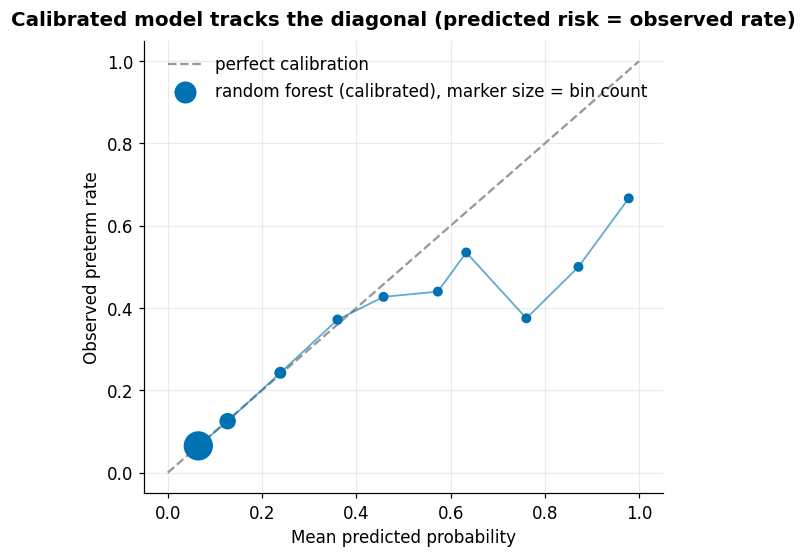

In [9]:
cur = M["reliability_rf"]
xp = [b["mean_pred"] for b in cur]; yo = [b["observed"] for b in cur]
print("Reliability bins (mean predicted vs observed), random forest, held-out:")
for b in cur:
    print(f"  pred {b['mean_pred']:.3f} -> observed {b['observed']:.3f}  (n={b['count']:,})")
cnts = np.array([b["count"] for b in cur], dtype=float)
sizes = 30 + 300 * (cnts / cnts.max())   # marker area scaled by bin mass
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0,1],[0,1],'--',color=PALETTE['grey'],label='perfect calibration')
ax.plot(xp, yo, color=PALETTE['blue'], linewidth=1.2, alpha=0.6)   # faint connecting line
ax.scatter(xp, yo, s=sizes, color=PALETTE['blue'], zorder=3,
           label='random forest (calibrated), marker size = bin count')
style(ax, 'Calibrated model tracks the diagonal (predicted risk = observed rate)',
      'Mean predicted probability', 'Observed preterm rate')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**One honest qualification, which I want to state loudly.** A low ECE means the scores are well-calibrated *in aggregate*. It does NOT mean the model stratifies individuals well. In fact the risk-spread diagnostic below shows most predictions sit within a few points of the base rate, so the model is essentially saying 'about average risk' for almost everyone, and it is right on average. That is useful for population-level analysis and honest about its limits for individual prediction.

In [10]:
near = M['fraction_near_base_rate']
print(f'{near*100:.0f}% of the best model\'s predictions fall within +/-5 points of the '
      f'{M["prevalence"]*100:.1f}% base rate.')
print('So low ECE = trustworthy AVERAGES, not reliable individual risk scores. Both things are true.')

83% of the best model's predictions fall within +/-5 points of the 8.6% base rate.
So low ECE = trustworthy AVERAGES, not reliable individual risk scores. Both things are true.


<a id="byrace"></a>
## Does calibration hold across race groups?

This is the question that decides whether a fairness audit is even possible. If the model were well-calibrated overall but badly miscalibrated within a race group, then a predicted 10% would mean different things for different mothers, and every downstream fairness metric would be built on sand. So we check calibration *within* each race group, on the held-out data.

In [11]:
strat = [s for s in M['stratified'] if s['status'] != 'suppressed']
print(f"{'group':<16}{'n':>10}{'AUC-ROC':>9}{'ECE':>9}   status")
for s in sorted(strat, key=lambda r: -r['n']):
    print(f"{s['group']:<16}{s['n']:>10,}{s['auc_roc']:>9.3f}{s['ece']:>9.4f}   {s['status']}")

group                    n  AUC-ROC      ECE   status
NH White           756,298    0.631   0.0009   ok
Hispanic           377,388    0.605   0.0014   ok
NH Black           208,755    0.620   0.0046   ok
NH Asian            92,342    0.599   0.0027   ok
NH Multiracial      35,333    0.618   0.0038   ok
NH AIAN             10,806    0.627   0.0035   ok
NH NHOPI             4,040    0.611   0.0098   wide_ci


**Calibration holds across the large groups** (ECE under about 0.005 for every group with enough data), so the risk scores mean the same thing across race, which is the green light the fairness audit needs. Two honest caveats carried from earlier weeks. First, discrimination is slightly lower for Hispanic and NH Asian mothers (AUC-ROC around 0.60 versus about 0.63 for NH White). I am flagging that only as a hypothesis for the planned Week 4 fairness audit, where it gets confidence intervals and a proper significance test; it is not a claim yet. Second, the smallest groups (NH NHOPI) get a wide-confidence-interval flag rather than a clean read, exactly as our tiered-reporting rule intends. Race here remains a marker of exposure to racism, not a biological cause, and nothing here is a clinical tool.

<a id="plan"></a>
## The plan from here

Week 3 established the honest floor: a calibrated model at about AUC-ROC 0.65, well-calibrated in aggregate and across race, and honest about its weak individual-level power. That floor is trustworthy precisely because Week 2 kept the leaky fields out.

**Next weeks:**

- **Gradient boosting with proper tuning.** XGBoost and LightGBM, tuned with Optuna, to see how much (if any) the ceiling moves. I expect a small gain over these baselines, consistent with the literature that trees lead on tabular data but cannot manufacture signal that is not there.
- **The first formal fairness audit.** Turn this week's calibration-by-group result into rigorous metrics: equal opportunity, demographic parity, disparate impact, each with a confidence interval and a proper significance test.
- **A decomposition of the racial gap**, asking how much of the disparity measured factors can account for, and how much is left unexplained.

The modest ceiling is not a disappointment; it is the finding. It tells us these records support population-level equity diagnosis, not individual risk scoring, and that is the honest thing to build on.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
